# SafeStep · 0 — SisFall ingestion, cleaning, splits
`raw .txt (200 Hz)` → `physical units` → `50 Hz` → `trial table + signals + subject split` → Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os, re, io, json, glob, time
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import signal as sps
from tqdm.auto import tqdm

BASE    = '/content/drive/MyDrive/Daffodil Robo Tech Olympiad'
RAW_DIR = f'{BASE}/SisFall/SisFall_dataset'
PROJ    = f'{BASE}/SafeStep'
D = {k: f'{PROJ}/{k}' for k in ['data', 'artifacts', 'figures', 'models', 'code']}
for p in D.values(): os.makedirs(p, exist_ok=True)

SEED, FS_RAW, FS = 42, 200, 50
np.random.seed(SEED)
sns.set_theme(style='whitegrid'); plt.rcParams['figure.dpi'] = 110
def save_fig(name):
    plt.savefig(f"{D['figures']}/{name}.png", dpi=300, bbox_inches='tight')
assert os.path.isdir(RAW_DIR), f'Not found: {RAW_DIR}'
print('raw:', RAW_DIR, '\nproject:', PROJ)

raw: /content/drive/MyDrive/Daffodil Robo Tech Olympiad/SisFall/SisFall_dataset 
project: /content/drive/MyDrive/Daffodil Robo Tech Olympiad/SafeStep


In [3]:
ADL = {
 'D01': ('Walking slowly', 'Walking'),            'D02': ('Walking quickly', 'Walking'),
 'D03': ('Jogging slowly', 'Jogging'),            'D04': ('Jogging quickly', 'Jogging'),
 'D05': ('Stairs up/down slowly', 'Stairs'),      'D06': ('Stairs up/down quickly', 'Stairs'),
 'D07': ('Sit half-height chair slowly', 'Sit/Stand'), 'D08': ('Sit half-height chair quickly', 'Sit/Stand'),
 'D09': ('Sit low chair slowly', 'Sit/Stand'),    'D10': ('Sit low chair quickly', 'Sit/Stand'),
 'D11': ('Collapse into chair', 'Sit/Stand'),     'D12': ('Lie down slowly, sit up', 'Lying'),
 'D13': ('Lie down quickly, sit up', 'Lying'),    'D14': ('Turn in bed (back-lateral-back)', 'Lying'),
 'D15': ('Bend with knees, get up', 'Bending'),   'D16': ('Bend without knees, get up', 'Bending'),
 'D17': ('Get in/out of a car', 'Car'),           'D18': ('Stumble while walking', 'Near-fall'),
 'D19': ('Gentle jump (reach high)', 'Near-fall'),
}
FALL = {
 'F01': ('Forward fall, slip (walking)', 'forward', 'walking'),
 'F02': ('Backward fall, slip (walking)', 'backward', 'walking'),
 'F03': ('Lateral fall, slip (walking)', 'lateral', 'walking'),
 'F04': ('Forward fall, trip (walking)', 'forward', 'walking'),
 'F05': ('Forward fall, trip (jogging)', 'forward', 'walking'),
 'F06': ('Vertical fall, fainting (walking)', 'vertical', 'fainting'),
 'F07': ('Fainting fall, hands on table', 'assisted', 'fainting'),
 'F08': ('Forward fall, getting up', 'forward', 'getting_up'),
 'F09': ('Lateral fall, getting up', 'lateral', 'getting_up'),
 'F10': ('Forward fall, sitting down', 'forward', 'sitting_down'),
 'F11': ('Backward fall, sitting down', 'backward', 'sitting_down'),
 'F12': ('Lateral fall, sitting down', 'lateral', 'sitting_down'),
 'F13': ('Forward fall, fainting (seated)', 'forward', 'seated'),
 'F14': ('Backward fall, fainting (seated)', 'backward', 'seated'),
 'F15': ('Lateral fall, fainting (seated)', 'lateral', 'seated'),
}
# sensor conversion (SisFall readme): value = (2*range / 2**bits) * raw
K_ACC1 = 2 * 16 / 2**13      # ADXL345  ±16 g, 13-bit  -> g
K_GYRO = 2 * 2000 / 2**16    # ITG3200  ±2000 °/s, 16-bit -> °/s
K_ACC2 = 2 * 8 / 2**14       # MMA8451Q ±8 g, 14-bit  -> g
CHANNELS = ['acc_x', 'acc_y', 'acc_z', 'gyro_x', 'gyro_y', 'gyro_z', 'acc2_x', 'acc2_y', 'acc2_z']
SCALE = np.array([K_ACC1]*3 + [K_GYRO]*3 + [K_ACC2]*3, np.float64)

In [4]:
PAT = re.compile(r'^([DF]\d{2})_(S[AE]\d{2})_R(\d{2})\.txt$')
files = []
for p in glob.glob(f'{RAW_DIR}/*/*.txt'):
    m = PAT.match(os.path.basename(p))
    if m: files.append((p, *m.groups()))
files.sort(key=lambda r: (r[2], r[1], r[3]))
subjects = sorted({f[2] for f in files})
print(f'{len(files)} recordings | {len(subjects)} subjects | '
      f'{sum(s.startswith("SA") for s in subjects)} young, {sum(s.startswith("SE") for s in subjects)} elderly')

4505 recordings | 38 subjects | 23 young, 15 elderly


In [5]:
def parse_file(path):
    with open(path, 'r', errors='ignore') as f:
        txt = f.read().replace(';', '')
    df = pd.read_csv(io.StringIO(txt), header=None, skipinitialspace=True, on_bad_lines='skip')
    df = df.iloc[:, :9].apply(pd.to_numeric, errors='coerce').dropna()
    if df.shape[1] < 9 or len(df) < FS_RAW:
        return None
    x = df.values.astype(np.float64) * SCALE
    try:
        y = sps.decimate(x, FS_RAW // FS, ftype='fir', axis=0, zero_phase=True)
    except ValueError:
        y = x[::FS_RAW // FS]
    return y.astype(np.float32), len(df)

t0 = time.time()
with ThreadPoolExecutor(max_workers=16) as ex:
    parsed = list(tqdm(ex.map(lambda r: parse_file(r[0]), files), total=len(files), desc='parsing'))
print(f'parsed in {time.time()-t0:.0f}s | failed: {sum(p is None for p in parsed)}')

parsing:   0%|          | 0/4505 [00:00<?, ?it/s]

parsed in 88s | failed: 0


In [6]:
rows, chunks, offset = [], [], 0
for (path, code, subj, rep), res in zip(files, parsed):
    if res is None:
        continue
    x, n_raw = res
    svm = np.linalg.norm(x[:, :3], axis=1)
    is_fall = code.startswith('F')
    name, group = (FALL[code][0], 'Fall') if is_fall else ADL.get(code, (code, 'Other'))
    rows.append(dict(
        trial_id=len(rows), file=os.path.basename(path), code=code, subject=subj, rep=int(rep),
        age_group='young' if subj.startswith('SA') else 'elderly',
        type='Fall' if is_fall else 'ADL', name=name, group=group,
        direction=FALL[code][1] if is_fall else 'none', context=FALL[code][2] if is_fall else 'none',
        n_samples=len(x), duration_s=len(x) / FS, n_raw=n_raw,
        peak_g=float(svm.max()), peak_idx=int(svm.argmax()),
        gyro_peak_dps=float(np.linalg.norm(x[:, 3:6], axis=1).max()),
        offset=offset))
    chunks.append(x); offset += len(x)

meta = pd.DataFrame(rows)
signals = np.concatenate(chunks)
print(meta.shape, signals.shape, f'{signals.nbytes/1e6:.0f} MB')
meta.head()

(4505, 18) (3964862, 9) 143 MB


,trial_id,file,code,subject,rep,age_group,type,name,group,direction,context,n_samples,duration_s,n_raw,peak_g,peak_idx,gyro_peak_dps,offset
0,0,D01_SA01_R01.txt,D01,SA01,1,young,ADL,Walking slowly,Walking,none,none,5000,100.0,19999,2.032830,4166,94.923225,0
1,1,D02_SA01_R01.txt,D02,SA01,1,young,ADL,Walking quickly,Walking,none,none,5000,100.0,20000,2.690475,4855,153.273071,5000
2,2,D03_SA01_R01.txt,D03,SA01,1,young,ADL,Jogging slowly,Jogging,none,none,5000,100.0,20000,3.316838,3921,216.950012,10000
3,3,D04_SA01_R01.txt,D04,SA01,1,young,ADL,Jogging quickly,Jogging,none,none,5000,100.0,20000,4.498673,4974,325.272827,15000
4,4,D05_SA01_R01.txt,D05,SA01,1,young,ADL,Stairs up/down slowly,Stairs,none,none,1250,25.0,5000,1.983795,740,114.175926,20000


In [7]:
qc = {
 'subjects': meta.subject.nunique(),
 'recordings': len(meta),
 'ADL recordings': int((meta.type == 'ADL').sum()),
 'fall recordings': int((meta.type == 'Fall').sum()),
 'elderly with falls': sorted(meta[(meta.age_group == 'elderly') & (meta.type == 'Fall')].subject.unique()),
 'NaN in signals': int(np.isnan(signals).sum()),
 'hours of data': round(meta.duration_s.sum() / 3600, 2),
 'acc saturation (>15.9 g) samples': int((np.abs(signals[:, :3]) > 15.9).sum()),
}
for k, v in qc.items(): print(f'{k:35s} {v}')
pd.crosstab(meta.code, meta.age_group).T

subjects                            38
recordings                          4505
ADL recordings                      2707
fall recordings                     1798
elderly with falls                  ['SE06']
NaN in signals                      0
hours of data                       22.03
acc saturation (>15.9 g) samples    0


code,D01,D02,D03,D04,D05,D06,D07,D08,D09,D10,...,F06,F07,F08,F09,F10,F11,F12,F13,F14,F15
age_group,,,,,,,,,,,,,,,,,,,,,
elderly,15,15,15,13,75,5,75,75,70,70,...,5,5,5,5,5,5,5,5,5,5
young,23,23,23,23,115,113,115,115,115,115,...,115,115,115,115,114,115,115,115,115,115


In [8]:
young = sorted(s for s in subjects if s.startswith('SA'))
elder = sorted(s for s in subjects if s.startswith('SE'))
elder_fallers = qc['elderly with falls']
rng = np.random.default_rng(SEED)
yp = [str(s) for s in rng.permutation(young)]
ep = [str(s) for s in rng.permutation([s for s in elder if s not in elder_fallers])]
SPLIT = {
 'train': sorted(yp[9:] + ep[7:]),
 'val':   sorted(yp[5:9] + ep[4:7]),
 'test':  sorted(yp[:5] + ep[:4] + list(elder_fallers)),
}
subj2split = {s: k for k, v in SPLIT.items() for s in v}
meta['split'] = meta.subject.map(subj2split)
assert not (set(SPLIT['train']) & set(SPLIT['test'])) and not (set(SPLIT['train']) & set(SPLIT['val']))
pd.crosstab([meta.split, meta.age_group], meta.type)

type              ADL  Fall
split age_group            
test  elderly     319    75
      young       394   375
train elderly     402     0
      young      1099  1048
val   elderly     177     0
      young       316   300

## Visual checks

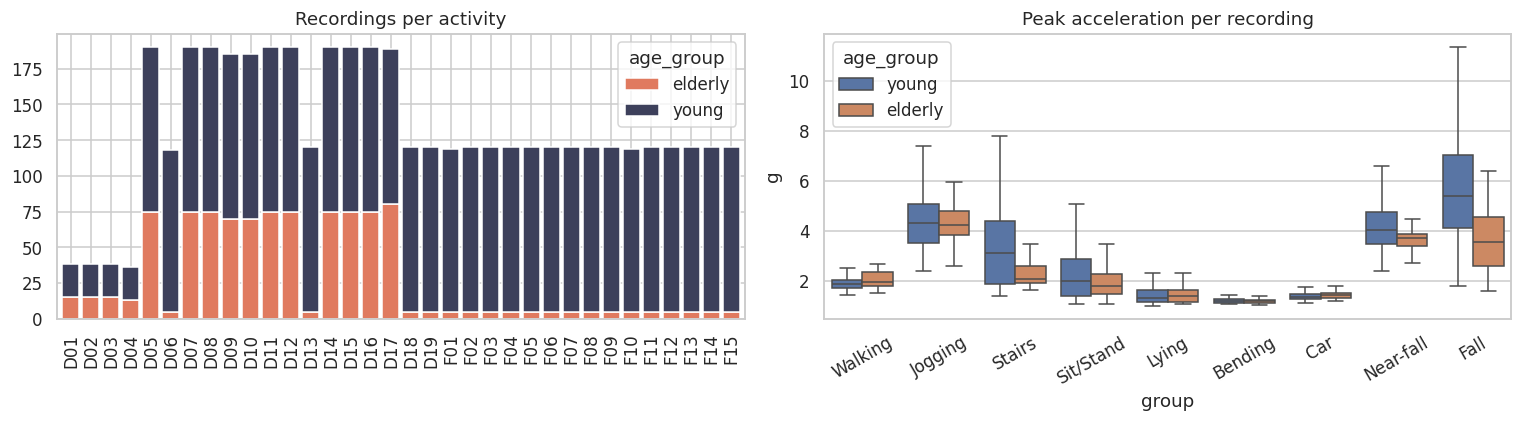

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
order = list(ADL) + list(FALL)
c = meta.groupby(['code', 'age_group']).size().unstack(fill_value=0).reindex(order).fillna(0)
c.plot.bar(stacked=True, ax=ax[0], color=['#e07a5f', '#3d405b'], width=0.85)
ax[0].set_title('Recordings per activity'); ax[0].set_xlabel('')
sns.boxplot(data=meta, x='group', y='peak_g', hue='age_group', ax=ax[1], showfliers=False,
            order=['Walking', 'Jogging', 'Stairs', 'Sit/Stand', 'Lying', 'Bending', 'Car', 'Near-fall', 'Fall'])
ax[1].set_title('Peak acceleration per recording'); ax[1].set_ylabel('g'); ax[1].tick_params(axis='x', rotation=30)
plt.tight_layout(); save_fig('00_dataset_overview'); plt.show()

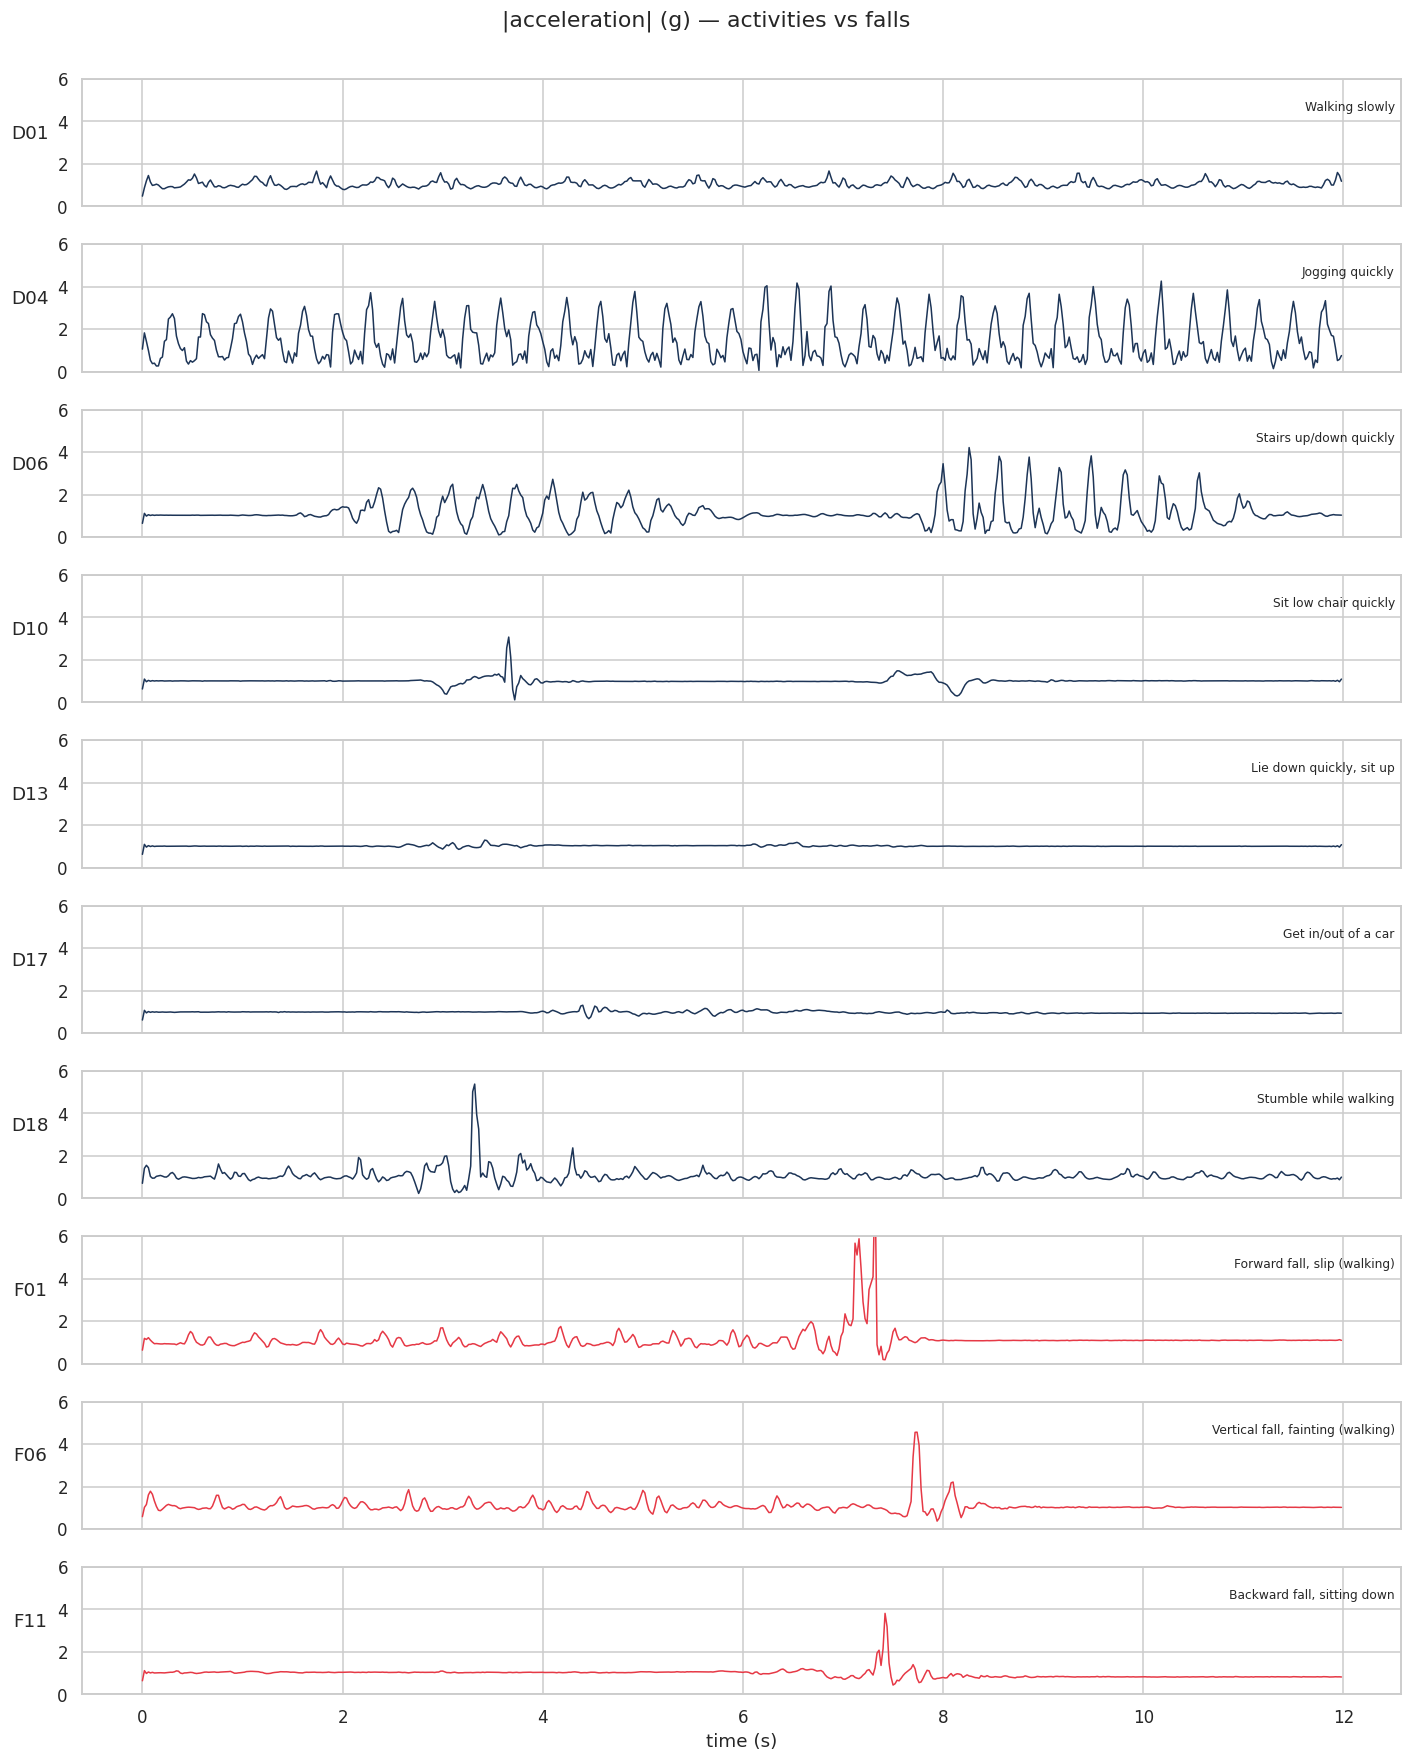

In [10]:
def trial(tid):
    r = meta.loc[tid]; return signals[r.offset:r.offset + r.n_samples]
show = [c for c in ['D01', 'D04', 'D06', 'D10', 'D13', 'D17', 'D18', 'F01', 'F06', 'F11']
        if ((meta.code == c) & (meta.age_group == 'young')).any()]
fig, axes = plt.subplots(len(show), 1, figsize=(13, 1.6 * len(show)), sharex=True)
for ax, code in zip(axes, show):
    r = meta[(meta.code == code) & (meta.age_group == 'young')].iloc[0]
    x = trial(r.trial_id)[: 12 * FS]
    t = np.arange(len(x)) / FS
    ax.plot(t, np.linalg.norm(x[:, :3], axis=1), lw=1, color='#e63946' if code[0] == 'F' else '#1d3557')
    ax.set_ylabel(code, rotation=0, labelpad=18); ax.set_ylim(0, 6)
    ax.text(0.995, 0.75, r['name'], transform=ax.transAxes, ha='right', fontsize=8)
axes[-1].set_xlabel('time (s)'); fig.suptitle('|acceleration| (g) — activities vs falls', y=1.0)
plt.tight_layout(); save_fig('01_signal_gallery'); plt.show()

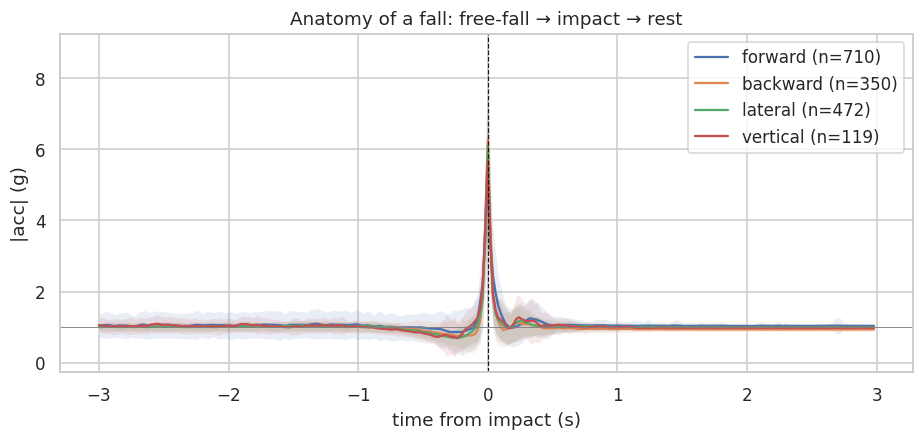

In [11]:
pre, post = 3 * FS, 3 * FS
segs = {}
for direction in ['forward', 'backward', 'lateral', 'vertical']:
    S = []
    for r in meta[(meta.type == 'Fall') & (meta.direction == direction)].itertuples():
        x = trial(r.trial_id); p = r.peak_idx
        if p - pre >= 0 and p + post <= len(x):
            S.append(np.linalg.norm(x[p - pre:p + post, :3], axis=1))
    segs[direction] = np.array(S)
t = (np.arange(pre + post) - pre) / FS
plt.figure(figsize=(10, 4))
for k, S in segs.items():
    if len(S):
        mu, sd = S.mean(0), S.std(0)
        plt.plot(t, mu, label=f'{k} (n={len(S)})'); plt.fill_between(t, mu - sd, mu + sd, alpha=0.12)
plt.axvline(0, color='k', ls='--', lw=0.8); plt.axhline(1, color='gray', lw=0.6)
plt.xlabel('time from impact (s)'); plt.ylabel('|acc| (g)'); plt.title('Anatomy of a fall: free-fall → impact → rest')
plt.legend(); save_fig('02_fall_anatomy'); plt.show()

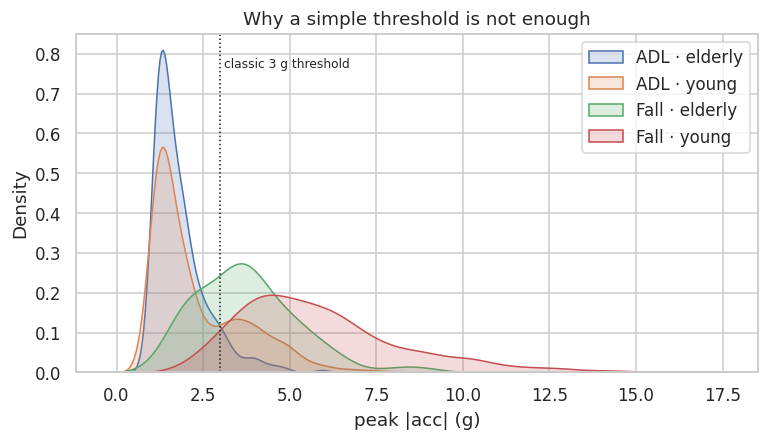

In [12]:
fig, ax = plt.subplots(figsize=(8, 4))
for (typ, age), g in meta.groupby(['type', 'age_group']):
    sns.kdeplot(g.peak_g.clip(0, 16), ax=ax, label=f'{typ} · {age}', fill=True, alpha=0.2, warn_singular=False)
ax.axvline(3, color='k', ls=':', lw=1); ax.text(3.1, ax.get_ylim()[1] * 0.9, 'classic 3 g threshold', fontsize=8)
ax.set_xlabel('peak |acc| (g)'); ax.legend(); ax.set_title('Why a simple threshold is not enough')
save_fig('03_threshold_problem'); plt.show()

In [13]:
np.savez_compressed(f"{D['data']}/signals_50hz.npz", signals=signals, channels=np.array(CHANNELS))
meta.to_parquet(f"{D['data']}/trials_meta.parquet", index=False)
json.dump(SPLIT, open(f"{D['artifacts']}/split_subjects.json", 'w'), indent=2)
json.dump({'fs': FS, 'fs_raw': FS_RAW, 'channels': CHANNELS,
           'units': {'acc': 'g', 'gyro': 'deg/s'}, 'adl': ADL,
           'fall': {k: list(v) for k, v in FALL.items()}, 'seed': SEED, 'qc': {k: v if not isinstance(v, (np.integer,)) else int(v) for k, v in qc.items()}},
          open(f"{D['artifacts']}/dataset_info.json", 'w'), indent=2, default=str)
for p in sorted(glob.glob(f'{PROJ}/*/*')):
    print(f'{os.path.relpath(p, PROJ):45s} {os.path.getsize(p)/1e6:8.1f} MB')

artifacts/dataset_info.json                        0.0 MB
artifacts/split_subjects.json                      0.0 MB
data/signals_50hz.npz                            133.9 MB
data/trials_meta.parquet                           0.2 MB
figures/00_dataset_overview.png                    0.2 MB
figures/01_signal_gallery.png                      0.9 MB
figures/02_fall_anatomy.png                        0.2 MB
figures/03_threshold_problem.png                   0.2 MB
